# Module 5 Lab 3: Textbook Problem 5.5

### Age, Income, and Vehicles: What Correlates?

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This project checks if age, income, and number of vehicles are related. 

## Load the data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

cust = pd.read_csv('custdata.tsv', sep='\t')
cols = ['age', 'income', 'num.vehicles']

print(cust.shape)   # 1,000 customers, 11 columns
cust[cols].describe().round(1)

(1000, 11)


,age,income,num.vehicles
count,1000.0,1000.0,944.0
mean,51.7,53504.8,1.9
std,18.9,65478.1,1.1
min,0.0,-8700.0,0.0
25%,38.0,14600.0,1.0
50%,50.0,35000.0,2.0
75%,64.0,67000.0,2.0
max,146.7,615000.0,6.0


I started with `describe()` to look for anything off. 

## Before cleaning: correlation matrix

In [2]:
before = cust[cols].corr()
before.round(3)

,age,income,num.vehicles
age,1.000,0.027,-0.064
income,0.027,1.000,0.139
num.vehicles,-0.064,0.139,1.000


## Finding the invalid values

In [3]:
print('age = 0:        ', (cust['age'] <= 0).sum())
print('age over 100:   ', (cust['age'] > 100).sum())
print('income below 0: ', (cust['income'] < 0).sum())
print('vehicles missing:', cust['num.vehicles'].isna().sum())

age = 0:         3
age over 100:    8
income below 0:  1
vehicles missing: 56


In [4]:
# look at the ages over 100
cust.loc[cust['age'] > 100, ['custid', 'age', 'income']]

,custid,age,income
212,287882,137.700030,60000
266,364991,123.061023,12000
286,397230,136.052160,31200
593,843811,146.680197,40000
625,875771,124.845087,175200
752,1047534,130.401605,200000
926,1303929,126.737284,43400
953,1361012,113.337207,255000


Note: I pulled up the 8 ages over 100. They're all between 113 and 147 and have long decimals (like 137.70003), while every real age in the file is a whole number. That makes them look like errors, not real people.

## Cleaning

**What I removed and why:**

**Impossible values (removed)**

- **Age of 0 (3 rows):** No customer is 0 years old, so this is most likely a missing age saved as 0.
- **Age over 100 (8 rows):** Ages from 113 to 147 aren't realistic, and the decimals point to an error.
- **Negative income (1 row):** Income can't be below 0.

**Possible values (kept)**

- **Income of exactly 0 (78 rows):** That's realistic for someone who's retired, unemployed, or in school.
- **Age of 93 (10 rows):** The data looks like it caps age at 93, so these are real older customers.

**Missing values (removed)**

- **Missing `num.vehicles` (56 rows):** These aren't wrong, just blank. I dropped them so all three correlations are calculated on the same customers.

In [5]:
clean = cust[(cust['age'] > 0) & (cust['age'] <= 100) & (cust['income'] >= 0)]
clean = clean.dropna(subset=['num.vehicles'])

removed = len(cust) - len(clean)
print(f'Before: {len(cust)} rows')
print(f'After:  {len(clean)} rows')
print(f'Removed {removed} rows ({removed / len(cust):.1%})')

clean[cols].describe().round(1)

Before: 1000 rows
After:  932 rows
Removed 68 rows (6.8%)


,age,income,num.vehicles
count,932.0,932.0,932.0
mean,51.4,55949.3,1.9
std,16.8,66040.1,1.1
min,19.0,0.0,0.0
25%,39.0,17000.0,1.0
50%,50.0,37000.0,2.0
75%,63.0,70000.0,2.0
max,93.0,615000.0,6.0


After cleaning I ran `describe()` again to double-check. Ages now go from 19 to 93 and income starts at 0, so everything left is realistic.

## After cleaning: correlation matrix

In [6]:
after = clean[cols].corr()
after.round(3)

,age,income,num.vehicles
age,1.000,-0.003,-0.066
income,-0.003,1.000,0.138
num.vehicles,-0.066,0.138,1.000


## Before vs. after

In [11]:
pairs = [('age', 'income'), ('age', 'num.vehicles'), ('income', 'num.vehicles')]
compare = pd.DataFrame({
    'pair': [f'{a} vs {b}' for a, b in pairs],
    'r before': [before.loc[a, b] for a, b in pairs],
    'r after':  [after.loc[a, b] for a, b in pairs],
})
compare['change'] = compare['r after'] - compare['r before']
compare.round(3)

,pair,r before,r after,change
0,age vs income,0.027,-0.003,-0.030
1,age vs num.vehicles,-0.064,-0.066,-0.003
2,income vs num.vehicles,0.139,0.138,-0.001


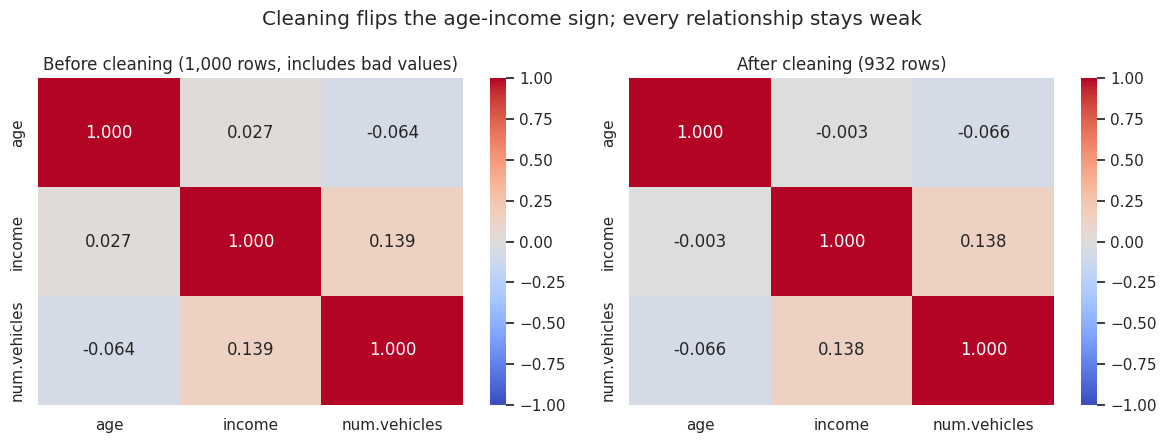

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(before, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Before cleaning (1,000 rows, includes bad values)')

sns.heatmap(after, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title(f'After cleaning ({len(clean)} rows)')

fig.suptitle('Cleaning flips the age-income sign; every relationship stays weak')
plt.tight_layout()
plt.show()

Note: Looking at the two matrices side by side, most numbers barely moved, but age vs. income flipped from +0.027 to -0.003. 

## Seeing the bad ages

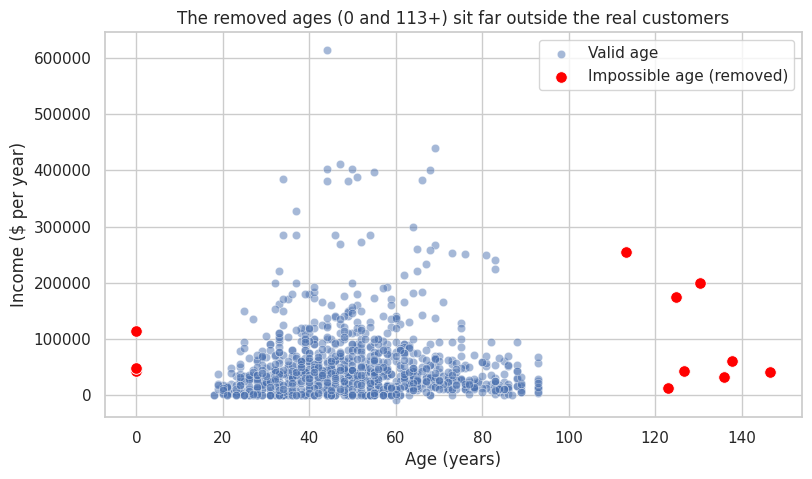

In [9]:
bad = (cust['age'] <= 0) | (cust['age'] > 100)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=cust[~bad], x='age', y='income', alpha=0.5, label='Valid age')
sns.scatterplot(data=cust[bad], x='age', y='income', color='red', s=70, label='Impossible age (removed)')
plt.title('The removed ages (0 and 113+) sit far outside the real customers')
plt.xlabel('Age (years)')
plt.ylabel('Income ($ per year)')
plt.legend()
plt.show()

## Checking for a curve ball

Since r only picks up straight-line relationships and since age vs. income came out right around 0, I split age into four groups and checked the average income in each to see if a curve was hiding in there.

In [10]:
age_groups = pd.cut(clean['age'], bins=[17, 30, 45, 65, 93],
                    labels=['18-30', '31-45', '46-65', '66-93'])
clean.groupby(age_groups, observed=True)['income'].agg(['count', 'mean', 'median']).round(0)

,count,mean,median
age,,,
18-30,105,29236.0,22000.0
31-45,261,63263.0,45000.0
46-65,376,60952.0,42100.0
66-93,190,50765.0,27750.0


There is one. Income is lowest for 18 to 30, highest from 31 to 65, and drops again after 65. Because it goes up and then back down, a straight line through it is nearly flat, which is why r is close to 0.

## Interpretation (cleaned data only)

**Is there a correlation?** 

Not really a correlation. After cleaning, income and number of vehicles have the strongest relationship, and it's still weak (r = 0.14): people who earn more tend to own slightly more vehicles, with plenty of exceptions. Age has almost no straight-line relationship with income (r ≈ 0.00) or vehicles (r = -0.07), but the age-group table shows income does change with age, which r can't pick up.

## AI Use

I used AI to help with syntax and refine wording on this lab.